# Tarea 2 · Parte 1 — Voces y documentos peruanos: del archivo escaneado al texto buscable

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 26 de octubre de 2026 (descarga, OCR y ASR) |
| **Documentos** | 25 imágenes de Wikimedia Commons: 8 impresos nítidos, 8 fotos con sombra o inclinación, 9 manuscritos (+5 suplentes). Licencias: dominio público, CC0, CC BY 2.0/4.0, CC BY-SA 3.0/4.0 |
| **Audio** | 20 entrevistas y testimonios en español peruano de Wikimedia Commons (CC BY-SA 4.0 y CC BY 4.0) + 6 frases leídas de OpenSLR 73 (Google, CC BY-SA 4.0) |
| **OCR** | PaddleOCR 3.7.0 (PP-OCRv6 *medium* det + rec, `lang="es"`, motor PyTorch en GPU RTX 5050) |
| **ASR** | faster-whisper 1.2.1 · Whisper `small` (CTranslate2 int8, CPU) con VAD Silero · `language="es"`, `beam_size=5` |
| **Diarización** | Huellas de voz WeSpeaker ResNet34 (pyannote) + clustering jerárquico (`voz.py` de la sesión 13) |
| **Entorno** | Las librerías de `uv sync --group docai --group audio`, instaladas en `tarea_2/.venv-gpu` con PyTorch CUDA 12.8 (ver README) |

La fuente, el autor, la licencia y la URL de **cada** archivo están en `datos/fuentes.csv` (se arma en la sección 8).
Los archivos originales no se versionan (`datos/raw/` está en `.gitignore`); se recuperan con
`python tarea_2/herramientas/descargar.py`, que respeta una pausa de 1,5 s entre solicitudes y usa un `User-Agent` descriptivo.

**Seudonimización:** ningún nombre de persona particular, DNI, teléfono ni correo se publica. Ver sección 5.

In [1]:
import os, sys, json, time, shutil, warnings
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # no consultar los servidores de modelos en cada arranque
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display, Markdown

RAIZ = Path.cwd()                          # el notebook corre desde tarea_2/
sys.path.insert(0, str(RAIZ / "herramientas"))
sys.path.insert(0, str(RAIZ.parent / "sessions" / "13-audio-a-texto"))
import t2
import voz

pio.renderers.default = "plotly_mimetype+png"    # interactivo en Jupyter y PNG para que se vea en GitHub
pd.set_option("display.max_colwidth", 90)

DATOS, RAW = RAIZ / "datos", RAIZ / "datos" / "raw"
DIR_DOCS, DIR_AUDIO = RAW / "documentos", RAW / "audio"

import paddleocr, faster_whisper, ctranslate2, torch
print("PaddleOCR", paddleocr.__version__, "| PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))
print("faster-whisper", faster_whisper.__version__, "| CTranslate2", ctranslate2.__version__)

PaddleOCR 3.7.0 | PyTorch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 5050 Laptop GPU
faster-whisper 1.2.1 | CTranslate2 4.8.4


## 1. Corpus y fuentes

`herramientas/descargar.py` baja todo y deja un catálogo con la licencia y la URL de cada archivo.
Si `datos/raw/` no existe (por ejemplo, al clonar el repositorio), esta celda lo vuelve a descargar.

In [2]:
CATALOGO = RAW / "catalogo_descargas.csv"
if not CATALOGO.exists():
    import subprocess
    subprocess.run([sys.executable, str(RAIZ / "herramientas" / "descargar.py")], check=True)
catalogo = pd.read_csv(CATALOGO)
print(catalogo.groupby(["modalidad", catalogo["tipo"].fillna("-")]).size().rename("archivos").to_string())
catalogo.groupby(["modalidad", "licencia"]).size().rename("archivos").reset_index()

modalidad  tipo      
audio      -             26
documento  foto          10
           impreso       10
           manuscrito    10


,modalidad,licencia,archivos
0,audio,CC BY 4.0,8
1,audio,CC BY-SA 4.0,18
2,documento,Attribution,1
3,documento,CC BY 2.0,1
4,documento,CC BY 4.0,2
5,documento,CC BY-SA 3.0,3
6,documento,CC BY-SA 4.0,6
7,documento,CC0,5
8,documento,Public domain,12


## 2. Limpieza de documentos: duplicados por hash

Dos archivos con el mismo SHA-256 son el mismo documento (Commons tiene versiones repetidas con otro nombre).
Se revisan los 25 documentos y los 5 suplentes.

In [3]:
docs = catalogo[catalogo["modalidad"] == "documento"].copy()
docs["sha256"] = [t2.sha256(RAIZ / a) for a in docs["archivo"]]
duplicados = docs[docs.duplicated("sha256", keep="first")]
print(f"{len(docs)} imágenes, {docs['sha256'].nunique()} distintas -> {len(duplicados)} duplicados")
display(duplicados[["id", "titulo_original"]]) if len(duplicados) else None
docs = docs.drop_duplicates("sha256")

30 imágenes, 30 distintas -> 0 duplicados


## 3. OCR con PaddleOCR

**Configuración (la misma para todo el corpus y que luego será la línea base de la Parte 2):**

- `lang="es"`: modelo de reconocimiento PP-OCRv6 para alfabeto latino con español.
- Preprocesamiento por defecto de PaddleOCR 3.7: clasificador de orientación de página (`PP-LCNet_x1_0_doc_ori`),
  "planchado" de hojas curvas (`UVDoc`) y orientación de cada línea (`PP-LCNet_x1_0_textline_ori`).
  No agregamos ningún preprocesamiento propio.
- `engine="transformers", device="gpu"`: los mismos pesos PP-OCRv6 corriendo sobre PyTorch en la GPU. En esta laptop
  (Windows) PaddlePaddle en CPU falla con oneDNN (`ConvertPirAttribute2RuntimeAttribute not support`) y sin oneDNN
  tardó hasta 27 minutos por página; en GPU tarda segundos.
- Orden de lectura: `t2.ordenar_lineas` agrupa las cajas en columnas (periódicos) y luego en renglones.

**Respaldo crudo:** por cada documento se guarda en `datos/raw/documentos/ocr/` el JSON completo de PaddleOCR
(cajas, textos, puntajes) y la imagen con las cajas dibujadas. Si el JSON ya existe, se reutiliza.

In [4]:
from paddleocr import PaddleOCR

CONFIG_OCR = dict(lang="es", engine="transformers", device="gpu")
MODELO_OCR = "PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"
DIR_OCR = DIR_DOCS / "ocr"
DIR_OCR.mkdir(parents=True, exist_ok=True)
motor = PaddleOCR(**CONFIG_OCR)


def ocr_documento(id_, ruta):
    "OCR con respaldo: si ya existe el JSON crudo, se lee de ahí."
    crudo = DIR_OCR / f"{id_}.json"
    if crudo.exists():
        r = json.loads(crudo.read_text(encoding="utf-8"))
        cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4)
        return {"texto": t2.ordenar_lineas(r["rec_texts"], cajas), "n_lineas": len(r["rec_texts"]),
                "confianza": float(np.mean(r["rec_scores"])) if r["rec_scores"] else 0.0, "segundos": r["segundos"]}
    t0 = time.perf_counter()
    salida = motor.predict(str(ruta))[0]
    segundos = time.perf_counter() - t0
    salida.save_to_img(str(DIR_OCR / f"{id_}_cajas.jpg"))
    r = {k: (np.asarray(salida[k]).tolist()) for k in ["rec_texts", "rec_scores", "rec_boxes"]}
    r["segundos"] = segundos
    crudo.write_text(json.dumps(r, ensure_ascii=False), encoding="utf-8")
    return ocr_documento(id_, ruta)


filas = []
for d in docs.itertuples():
    r = ocr_documento(d.id, RAIZ / d.archivo)
    filas.append({"id": d.id, "tipo": d.tipo, **r, "n_caracteres": len(r["texto"])})
    print(f"{d.id:18s} {d.tipo:10s} {r['n_lineas']:4d} líneas  conf {r['confianza']:.2f}  {r['segundos']:6.1f} s")
ocr = pd.DataFrame(filas)
print(f"\nTiempo total de OCR: {ocr['segundos'].sum() / 60:.1f} min")

Creating model: ('PP-LCNet_x1_0_doc_ori', None, 'transformers')


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\USER\.paddlex\official_models\PP-LCNet_x1_0_doc_ori_safetensors`.


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 5290.49it/s]


Creating model: ('UVDoc', None, 'transformers')


...


Creating model: ('PP-OCRv6_medium_rec', None, 'transformers')


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\USER\.paddlex\official_models\PP-OCRv6_medium_rec_safetensors`.


Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 269/269 [00:00<00:00, 5400.89it/s]

doc_01             impreso      15 líneas  conf 0.94     5.5 s
doc_02             impreso      23 líneas  conf 0.96     3.8 s
doc_03             impreso      17 líneas  conf 0.99     7.7 s
doc_04             impreso      72 líneas  conf 0.99     7.2 s
doc_05             impreso     121 líneas  conf 0.96    12.6 s
doc_06             impreso     137 líneas  conf 0.99    28.7 s
doc_07             impreso      75 líneas  conf 0.99    41.2 s
doc_08             impreso      10 líneas  conf 0.96     7.2 s
doc_09             foto        101 líneas  conf 0.99    48.4 s
doc_10             foto        242 líneas  conf 0.99    49.8 s
doc_11             foto         68 líneas  conf 0.99    39.7 s
doc_12             foto         38 líneas  conf 0.98    57.0 s
doc_13             foto         19 líneas  conf 0.99     0.9 s
doc_14             foto         37 líneas  conf 0.49     2.1 s
doc_15             foto        111 líneas  conf 0.75     1.8 s
doc_16             foto         13 líneas  conf 0.88   

### 3.1 Documentos ilegibles y reemplazo

Criterio: un documento es **ilegible** si el OCR devuelve menos de 20 caracteres **y** la revisión visual
confirma que el texto no se puede leer a esa resolución. Se descarta, se reporta y se reemplaza por un suplente
del mismo tipo, conservando su `id` para que siga habiendo 8 impresos, 8 fotos y 9 manuscritos.

In [5]:
UMBRAL = 20
oficiales = ocr[~ocr["id"].str.startswith("sup_")].copy()
suplentes = ocr[ocr["id"].str.startswith("sup_")].copy()
ilegibles = oficiales[oficiales["n_caracteres"] < UMBRAL]

descartes, reemplazos = [], {}
for f in ilegibles.itertuples():
    candidatos = suplentes[(suplentes["tipo"] == f.tipo) & (suplentes["n_caracteres"] >= UMBRAL)
                           & ~suplentes["id"].isin(reemplazos.values())]
    sup = candidatos.iloc[0]["id"]
    reemplazos[f.id] = sup
    titulo = docs.set_index("id").loc[f.id, "titulo_original"]
    descartes.append({"id": f.id, "tipo": f.tipo, "archivo_descartado": titulo, "caracteres_ocr": f.n_caracteres,
                      "motivo": "ilegible: imagen de muy baja resolución, el OCR no detecta texto",
                      "reemplazado_por": docs.set_index("id").loc[sup, "titulo_original"]})
descartes = pd.DataFrame(descartes)
print(f"Documentos descartados por ilegibles: {len(descartes)}")
descartes

Documentos descartados por ilegibles: 1


,id,tipo,archivo_descartado,caracteres_ocr,motivo,reemplazado_por
0,doc_20,manuscrito,Capitulacón de Ayacucho2.jpg,0,"ilegible: imagen de muy baja resolución, el OCR no detecta texto",Perucent.jpg


In [6]:
# el suplente toma el id del documento descartado; su archivo se copia con ese nombre
final = oficiales[~oficiales["id"].isin(reemplazos)].copy()
for id_viejo, id_sup in reemplazos.items():
    fila = suplentes[suplentes["id"] == id_sup].iloc[0].copy()
    fila["id"] = id_viejo
    final = pd.concat([final, fila.to_frame().T])
    origen = RAIZ / docs.set_index("id").loc[id_sup, "archivo"]
    shutil.copy(origen, DIR_DOCS / f"{id_viejo}_reemplazo{origen.suffix}")

meta = docs.set_index("id")
final["catalogo_id"] = final["id"].map(lambda i: reemplazos.get(i, i))
for col in ["titulo_original", "fuente_url", "url_archivo", "licencia", "autor", "publicable"]:
    final[col] = final["catalogo_id"].map(meta[col])
final["archivo"] = final["catalogo_id"].map(meta["archivo"])
final = final.sort_values("id").reset_index(drop=True)
final = final.astype({"n_caracteres": int, "n_lineas": int, "confianza": float, "segundos": float})
print(final.groupby("tipo").size().to_string())
print(f"Total: {len(final)} documentos")

tipo
foto          8
impreso       8
manuscrito    9
Total: 25 documentos


## 4. ASR: VAD, transcripción con faster-whisper y diarización

Pasos (con `voz.py` de la sesión 13):

1. **Decodificar** cada original (ogg, opus, wav o video webm) a WAV mono de 16 kHz.
2. **VAD (Silero):** medir cuántos segundos tienen voz. Un audio con menos de 1 s de voz o con voz en menos del 10 % de su
   duración se descarta como *sin voz* (silencio, música o ruido).
3. **Segmentar** los audios de más de 75 s en clips de máximo ~60 s, cortando siempre en una pausa del habla.
   Así cada clip es manejable para transcribir a mano en la Parte 2 y para escucharlo en el dashboard.
4. **Transcribir** cada clip con Whisper `small` en CPU (int8), `language="es"`, `beam_size=5` y el filtro VAD activado
   (no se le manda silencio al modelo, que es donde Whisper alucina frases).
5. **Diarizar** cada clip: huella de voz por segmento y clustering con umbral de distancia coseno 0,7. Si salen 2 o más
   hablantes, el texto lleva marcas `[HABLANTE_n]`.
6. **Exportar** cada clip a CSV, SRT y TXT en `datos/raw/audio/salidas/` (no se versiona).

In [7]:
import soundfile as sf

DIR_WAV = DIR_AUDIO / "wav16k"
DIR_WAV.mkdir(parents=True, exist_ok=True)
auds = catalogo[catalogo["modalidad"] == "audio"].copy()
auds["sha256"] = [t2.sha256(RAIZ / a) for a in auds["archivo"]]
dup_audio = auds[auds.duplicated("sha256")]
print(f"Audios duplicados por hash: {len(dup_audio)}")
auds = auds.drop_duplicates("sha256")

filas = []
for a in auds.itertuples():
    wav = DIR_WAV / f"{a.id}.wav"
    if not wav.exists():
        sf.write(wav, voz.cargar_audio(RAIZ / a.archivo), voz.SR)
    x, _ = sf.read(wav, dtype="float32")
    tramos = voz.tramos_de_voz(x)
    filas.append({"id": a.id, "duracion_seg": len(x) / voz.SR, "voz_seg": sum(b - a_ for a_, b in tramos)})
vad = pd.DataFrame(filas)
vad["proporcion_voz"] = vad["voz_seg"] / vad["duracion_seg"]
sin_voz = vad[(vad["voz_seg"] < 1) | (vad["proporcion_voz"] < 0.10)]
print(f"{len(vad)} audios, {vad['duracion_seg'].sum() / 60:.1f} min en total, {vad['voz_seg'].sum() / 60:.1f} min con voz")
print(f"Descartados por no tener voz: {len(sin_voz)}")
vad.round(2).sort_values("duracion_seg")

Audios duplicados por hash: 0


26 audios, 48.2 min en total, 42.5 min con voz
Descartados por no tener voz: 0


,id,duracion_seg,voz_seg,proporcion_voz
20,openslr_pef_02484_00640124552,5.55,3.79,0.68
23,openslr_pem_02436_01908231028,5.80,4.46,0.77
22,openslr_pef_00610_01507636015,6.40,4.91,0.77
24,openslr_pem_01208_00899753204,6.66,3.92,0.59
25,openslr_pem_00295_01058929077,8.02,5.78,0.72
21,openslr_pef_01523_00880599786,8.70,4.11,0.47
6,medio_tiempo,29.93,27.27,0.91
7,que_es_peru,43.58,31.09,0.71
9,magdalena_2,75.91,65.71,0.87
15,salas_5,77.47,64.42,0.83


In [8]:
MAX_CLIP, CORTAR_DESDE = 60.0, 75.0


def cortes_en_pausas(x, max_clip=MAX_CLIP):
    "Corta el audio en pausas del habla (fin de un tramo de voz) sin pasar de max_clip segundos por clip."
    tramos = voz.tramos_de_voz(x, silencio_min=0.4, max_tramo=20)
    total = len(x) / voz.SR
    cortes, inicio = [], 0.0
    for (a, b), siguiente in zip(tramos, tramos[1:] + [(total, total)]):
        if siguiente[0] - inicio > max_clip and b - inicio >= 15:   # el siguiente tramo ya no entra
            corte = (b + siguiente[0]) / 2                           # a mitad de la pausa
            cortes.append((inicio, corte))
            inicio = corte
    cortes.append((inicio, total))
    if len(cortes) > 1 and cortes[-1][1] - cortes[-1][0] < 15:      # no dejar un último clip de pocos segundos
        cortes[-2:] = [(cortes[-2][0], total)]
    return cortes


DIR_CLIPS = DIR_AUDIO / "clips"
DIR_CLIPS.mkdir(parents=True, exist_ok=True)
clips = []
for a in auds[~auds["id"].isin(sin_voz["id"])].itertuples():
    x, _ = sf.read(DIR_WAV / f"{a.id}.wav", dtype="float32")
    dur = len(x) / voz.SR
    partes = cortes_en_pausas(x) if dur > CORTAR_DESDE else [(0.0, dur)]
    for k, (ini, fin) in enumerate(partes, 1):
        clips.append({"origen": a.id, "parte": k, "inicio": round(ini, 2), "fin": round(fin, 2),
                      "duracion_seg": round(fin - ini, 2)})
clips = pd.DataFrame(clips)
clips.insert(0, "id", [f"clip_{i:02d}" for i in range(1, len(clips) + 1)])
for c in clips.itertuples():
    destino = DIR_CLIPS / f"{c.id}.wav"
    if not destino.exists():
        x, _ = sf.read(DIR_WAV / f"{c.origen}.wav", dtype="float32")
        sf.write(destino, x[int(c.inicio * voz.SR):int(c.fin * voz.SR)], voz.SR)
print(f"{len(clips)} clips de {clips['origen'].nunique()} audios · {clips['duracion_seg'].sum() / 60:.1f} min · "
      f"mediana {clips['duracion_seg'].median():.0f} s")
clips.groupby("origen").agg(clips=("id", "size"), minutos=("duracion_seg", lambda s: round(s.sum() / 60, 2)))

58 clips de 26 audios · 48.2 min · mediana 61 s


,clips,minutos
origen,,
agustino_1,2,2.27
agustino_2,3,3.15
ciudadano,2,1.72
fenmucarinap_1,4,4.18
fenmucarinap_2,8,8.29
magdalena_1,2,1.50
magdalena_2,2,1.27
magdalena_3,2,1.48
medio_tiempo,1,0.50


In [9]:
from faster_whisper import WhisperModel

CONFIG_ASR = dict(language="es", beam_size=5, vad_filter=True, vad_parameters={"min_silence_duration_ms": 300})
MODELO_ASR = "faster-whisper small (int8, CPU, VAD Silero on, beam=5)"
whisper = WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=8)
DIR_SAL = DIR_AUDIO / "salidas"
DIR_SAL.mkdir(parents=True, exist_ok=True)


def transcribir_clip(id_):
    "Transcribe y diariza un clip. Respaldo en salidas/{id}.csv: si existe, se reutiliza."
    tabla_csv = DIR_SAL / f"{id_}.csv"
    if tabla_csv.exists():
        t = pd.read_csv(tabla_csv)
        return [voz.Segmento(r.inicio, r.fin, str(r.texto), r.hablante if isinstance(r.hablante, str) else None)
                for r in t.itertuples()], json.loads((DIR_SAL / f"{id_}.json").read_text())
    x, _ = sf.read(DIR_CLIPS / f"{id_}.wav", dtype="float32")
    t0 = time.perf_counter()
    segs, info = whisper.transcribe(x, **CONFIG_ASR)
    segs = [voz.Segmento(round(s.start, 2), round(s.end, 2), s.text.strip()) for s in segs if s.text.strip()]
    t_asr = time.perf_counter() - t0
    segs = voz.diarizar(x, segs, umbral=0.7, device="cuda") if len(segs) > 1 else segs
    meta = {"segundos_asr": t_asr, "idioma": info.language, "prob_idioma": info.language_probability}
    voz.a_tabla(segs).to_csv(tabla_csv, index=False)
    (DIR_SAL / f"{id_}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
    (DIR_SAL / f"{id_}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
    (DIR_SAL / f"{id_}.json").write_text(json.dumps(meta))
    return segs, meta


def texto_con_hablantes(segs):
    "Une segmentos; si hay 2+ hablantes, marca cada turno con [HABLANTE_n]."
    hablantes = {s.hablante for s in segs if s.hablante}
    if len(hablantes) < 2:
        return " ".join(s.texto for s in segs), max(1, len(hablantes))
    turnos = []
    for s in segs:
        etiqueta = f"[HABLANTE_{s.hablante[1:]}]"
        if turnos and turnos[-1][0] == etiqueta:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append((etiqueta, [s.texto]))
    return " ".join(f"{e} {' '.join(t)}" for e, t in turnos), len(hablantes)


filas = []
for c in clips.itertuples():
    segs, meta = transcribir_clip(c.id)
    texto, n = texto_con_hablantes(segs)
    filas.append({"id": c.id, "texto_asr_crudo": texto, "n_hablantes": n, "n_segmentos": len(segs), **meta})
    print(f"{c.id} {c.origen:16s} {c.duracion_seg:5.1f} s  {n} hablante(s)  {meta['segundos_asr']:5.1f} s ASR  {texto[:60]}")
asr = clips.merge(pd.DataFrame(filas), on="id")
print(f"\nASR: {asr['segundos_asr'].sum() / 60:.1f} min de cómputo para {asr['duracion_seg'].sum() / 60:.1f} min de audio "
      f"(factor de tiempo real {asr['segundos_asr'].sum() / asr['duracion_seg'].sum():.2f})")

clip_01 agustino_1        62.2 s  2 hablante(s)   25.5 s ASR  [HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con u
clip_02 agustino_1        74.1 s  3 hablante(s)   34.3 s ASR  [HABLANTE_1] ¿Por cuánto? [HABLANTE_2] El que gane Perú con 
clip_03 agustino_2        65.8 s  1 hablante(s)   34.0 s ASR  Buenos días profesor y compañeros. Hoy estoy cerca de aquí p
clip_04 agustino_2        61.1 s  4 hablante(s)   33.0 s ASR  [HABLANTE_1] La padula. [HABLANTE_2] ¿Por qué? [HABLANTE_1] 
clip_05 agustino_2        62.1 s  4 hablante(s)   23.3 s ASR  [HABLANTE_1] Veo que ambas han dicho el mismo resultado y es
clip_06 fenmucarinap_1    67.9 s  2 hablante(s)   41.7 s ASR  [HABLANTE_1] Bueno, hola, estamos en los San Martín, entre F
clip_07 fenmucarinap_1    67.1 s  2 hablante(s)   44.1 s ASR  [HABLANTE_1] una fiesta. Era una fiesta para nosotros, ¿no? 
clip_08 fenmucarinap_1    59.8 s  2 hablante(s)   36.2 s ASR  [HABLANTE_1] no respetan los convenios, las leyes las tenemo
clip_09 fenmucar

### 4.1 Diarización: el caso multihablante

`agustino_2` es una entrevista en la calle con la entrevistadora y dos vendedoras. Revisamos cómo quedó la
separación de hablantes en sus clips (texto seudonimizado más abajo; aquí solo la estructura de turnos).

In [10]:
multi = asr[asr["n_hablantes"] >= 2]
print(f"Clips con 2+ hablantes detectados: {len(multi)} de {len(asr)}")
print(multi.groupby("origen")["id"].apply(list).to_string())
segs, _ = transcribir_clip(asr[asr["origen"] == "agustino_2"]["id"].iloc[0])
voz.a_tabla(segs)[["inicio", "fin", "hablante"]].assign(palabras=[len(s.texto.split()) for s in segs]).head(12)

Clips con 2+ hablantes detectados: 25 de 58
origen
agustino_1                                   [clip_01, clip_02]
agustino_2                                   [clip_04, clip_05]
ciudadano                                    [clip_18, clip_19]
fenmucarinap_1             [clip_06, clip_07, clip_08, clip_09]
fenmucarinap_2    [clip_10, clip_11, clip_12, clip_13, clip_16]
magdalena_2                                           [clip_26]
magdalena_3                                  [clip_28, clip_29]
medio_tiempo                                          [clip_22]
plaza_armas                                  [clip_30, clip_31]
que_es_peru                                           [clip_23]
salas_4                                               [clip_38]
unmsm_2                                      [clip_20, clip_21]


,inicio,fin,hablante,palabras
0,0.02,5.54,H1,16
1,5.54,10.18,H1,13
2,10.18,16.26,H1,12
3,16.26,22.22,H1,9
4,22.22,30.94,H1,10
5,30.94,34.51,H1,7
6,34.51,40.83,H1,21
7,40.83,46.95,H1,12
8,46.95,51.46,H1,9
9,51.46,58.46,H1,14


## 5. Seudonimización

Procedimiento:

1. **Revisión humana** de todos los textos OCR y ASR para listar los nombres de **personas particulares**
   (entrevistadas, personas nombradas en partidas, recibos, diplomas y resoluciones). La lista real → seudónimo
   vive en `datos/raw/seudonimos.json`, que **no se versiona** (publicarla revelaría los nombres).
2. **Reemplazo automático** con `t2.seudonimizar`, que usa la comparación difusa de `voz.seudonimizar`
   (atrapa variantes mal escritas por el OCR/ASR) y además borra DNI (8 dígitos), celulares (9 dígitos) y correos.
3. Criterio: **se conservan** los nombres de figuras históricas o públicas en su rol público (próceres y firmantes de
   1821, Leguía, presidentes, autoridades firmando una resolución, un pintor que regala un retrato al Presidente),
   porque no son datos personales privados y son el contenido histórico del documento. Las personas particulares
   (entrevistadas, entrevistadores, homenajeados y beneficiarios de documentos recientes) se reemplazan por `PERSONA_n`.
   Las URL de atribución de Wikimedia Commons conservan el título original del archivo, que exige la licencia.
4. Los textos se revisan otra vez después del reemplazo. El procedimiento automático no sustituye esa revisión.

In [11]:
RUTA_SEUDO = RAW / "seudonimos.json"
seudonimos = json.loads(RUTA_SEUDO.read_text(encoding="utf-8")) if RUTA_SEUDO.exists() else {}
print(f"Lista revisada: {len(seudonimos)} nombres de personas particulares")

final["texto_ocr"], final["entidades_reemplazadas"] = zip(*[t2.seudonimizar(t, seudonimos) for t in final["texto"]])
asr["texto_asr"], asr["entidades_reemplazadas"] = zip(*[t2.seudonimizar(t, seudonimos) for t in asr["texto_asr_crudo"]])

resumen = pd.DataFrame({
    "textos": [len(final), len(asr)],
    "textos con reemplazos": [(final["entidades_reemplazadas"] > 0).sum(), (asr["entidades_reemplazadas"] > 0).sum()],
    "entidades reemplazadas": [final["entidades_reemplazadas"].sum(), asr["entidades_reemplazadas"].sum()],
}, index=["documentos (OCR)", "audios (ASR)"])
resumen

Lista revisada: 14 nombres de personas particulares


,textos,textos con reemplazos,entidades reemplazadas
documentos (OCR),25,2,3
audios (ASR),58,10,19


## 6. Análisis exploratorio

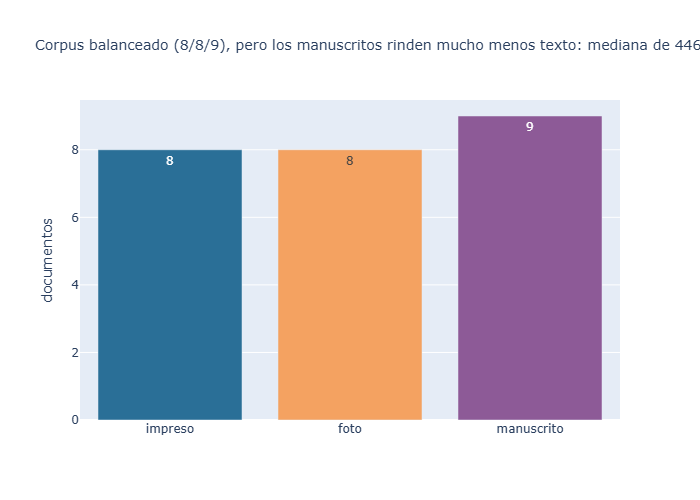

In [12]:
conteo = final["tipo"].value_counts().reindex(["impreso", "foto", "manuscrito"]).rename_axis("tipo").reset_index(name="documentos")
chars = final.groupby("tipo")["n_caracteres"].median()
fig = px.bar(conteo, x="tipo", y="documentos", text="documentos", color="tipo",
             color_discrete_sequence=["#2a6f97", "#f4a261", "#8d5a97"],
             title=(f"Corpus balanceado (8/8/9), pero los manuscritos rinden mucho menos texto: "
                    f"mediana de {chars['manuscrito']:.0f} caracteres OCR frente a {chars['impreso']:.0f} en impresos"))
fig.update_layout(showlegend=False, title_font_size=14, yaxis_title="documentos", xaxis_title="")
fig.show()

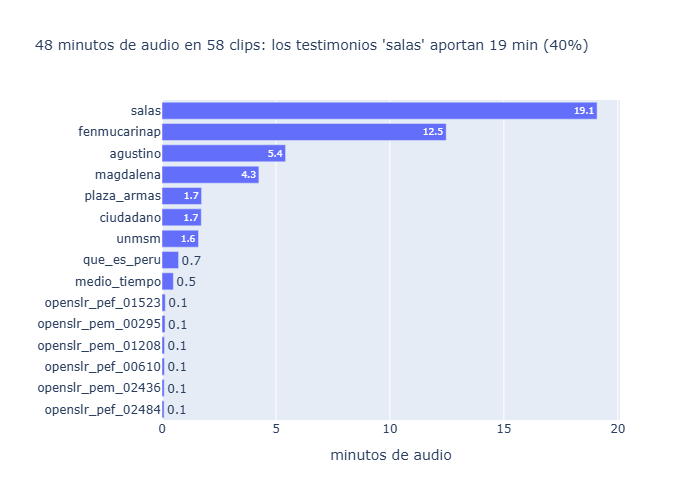

In [13]:
por_fuente = asr.assign(fuente=asr["origen"].str.replace(r"_\d+$", "", regex=True)) \
    .groupby("fuente")["duracion_seg"].sum().div(60).sort_values().reset_index(name="minutos")
top = por_fuente.iloc[-1]
fig = px.bar(por_fuente, x="minutos", y="fuente", orientation="h", text=por_fuente["minutos"].round(1),
             title=(f"{asr['duracion_seg'].sum() / 60:.0f} minutos de audio en {len(asr)} clips: los testimonios "
                    f"'{top['fuente']}' aportan {top['minutos']:.0f} min ({top['minutos'] / por_fuente['minutos'].sum():.0%})"))
fig.update_layout(title_font_size=14, xaxis_title="minutos de audio", yaxis_title="")
fig.show()

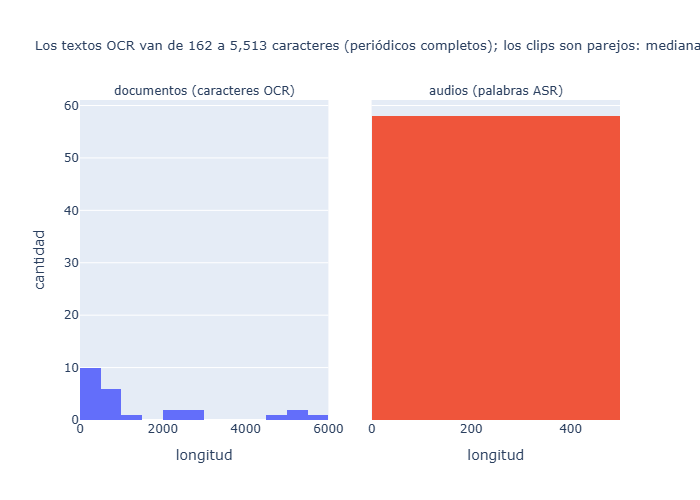

In [14]:
asr["n_palabras"] = asr["texto_asr"].map(lambda t: len(t2.normalizar(t).split()))
asr["palabras_por_min"] = asr["n_palabras"] / (asr["duracion_seg"] / 60)
largos = pd.concat([
    final.assign(modalidad="documentos (caracteres OCR)", longitud=final["n_caracteres"])[["modalidad", "longitud"]],
    asr.assign(modalidad="audios (palabras ASR)", longitud=asr["n_palabras"])[["modalidad", "longitud"]],
])
fig = px.histogram(largos, x="longitud", facet_col="modalidad", nbins=20, color="modalidad",
                   facet_col_spacing=0.08,
                   title=(f"Los textos OCR van de {final['n_caracteres'].min()} a {final['n_caracteres'].max():,} caracteres "
                          f"(periódicos completos); los clips son parejos: mediana de {asr['n_palabras'].median():.0f} palabras "
                          f"(~{asr['palabras_por_min'].median():.0f} por minuto)"))
fig.update_xaxes(matches=None, title_text="longitud")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(showlegend=False, title_font_size=13, yaxis_title="cantidad")
fig.show()

## 7. Validación: extremos de longitud

Comprobamos que los extremos de los histogramas tengan sentido: los textos más largos deberían ser páginas completas
de periódico y los más cortos, manuscritos o documentos con poco texto; en audio, los clips más largos deberían tener
más palabras.

In [15]:
cols = ["id", "tipo", "n_caracteres", "n_lineas", "confianza", "titulo_original"]
display(Markdown("**Documentos con OCR más largo**"), final.nlargest(3, "n_caracteres")[cols])
display(Markdown("**Documentos con OCR más corto**"), final.nsmallest(3, "n_caracteres")[cols])
cols = ["id", "origen", "duracion_seg", "n_palabras", "n_hablantes"]
display(Markdown("**Clips más largos**"), asr.nlargest(3, "duracion_seg")[cols])
display(Markdown("**Clips más cortos**"), asr.nsmallest(3, "duracion_seg")[cols])

**Documentos con OCR más largo**

,id,tipo,n_caracteres,n_lineas,confianza,titulo_original
9,doc_10,foto,5513,242,0.990314,"Publicación del Diario ""El Tiempo"" año 1973..JPG"
4,doc_05,impreso,5320,121,0.955037,El Comercio - Lima. Perú y Ecuador. 3-3-1842.jpg
5,doc_06,impreso,5085,137,0.986531,Inundación Carhuaz 1844.png


**Documentos con OCR más corto**

,id,tipo,n_caracteres,n_lineas,confianza,titulo_original
15,doc_16,foto,162,13,0.876696,Un Acto Solemne Viene Realizando Actividades por el Bicentenario 01.jpg
23,doc_24,manuscrito,218,12,0.868991,Peruvian Telephone Company receipt Lima 1895.JPG
22,doc_23,manuscrito,222,13,0.846161,Libro de Bautismos en la Gran Villa de Lampa 1871.jpg


**Clips más largos**

,id,origen,duracion_seg,n_palabras,n_hablantes
13,clip_14,fenmucarinap_2,78.22,128,1
38,clip_39,salas_4,76.56,232,1
1,clip_02,agustino_1,74.08,147,3


**Clips más cortos**

,id,origen,duracion_seg,n_palabras,n_hablantes
52,clip_53,openslr_pef_02484_00640124552,5.55,12,1
55,clip_56,openslr_pem_02436_01908231028,5.80,16,1
54,clip_55,openslr_pef_00610_01507636015,6.40,12,1


In [16]:
corr = asr[["duracion_seg", "n_palabras"]].corr().iloc[0, 1]
print(f"Correlación duración-palabras en los clips: {corr:.2f}")
print("Confianza media del OCR por tipo:")
print(final.groupby("tipo")["confianza"].mean().round(3).to_string())

Correlación duración-palabras en los clips: 0.88
Confianza media del OCR por tipo:
tipo
foto          0.881
impreso       0.970
manuscrito    0.757


## 8. Exportación

- `datos/documentos.csv` y `datos/transcripciones.csv`: columnas obligatorias + columnas de apoyo para el dashboard.
  Solo se exporta el texto **seudonimizado**. `texto_referencia` queda vacío: se completa en la Parte 2.
- `datos/fuentes.csv`: `id`, `modalidad`, `fuente_url`, `licencia` y `acceso` para cada archivo (incluidos suplentes y descartes).
- `datos/descartes.csv`: documentos y audios descartados con su motivo.

In [17]:
documentos = pd.DataFrame({
    "id": final["id"],
    "archivo": final["archivo"],
    "tipo": final["tipo"],
    "fuente": "Wikimedia Commons (" + final["licencia"] + ")",
    "texto_ocr": final["texto_ocr"],
    "modelo_ocr": MODELO_OCR,
    "texto_referencia": "",
    "n_caracteres": final["n_caracteres"].astype(int),
    "n_lineas": final["n_lineas"].astype(int),
    "confianza_ocr": final["confianza"].astype(float).round(3),
    "publicable": final["publicable"],
    "titulo_original": final["titulo_original"],
    "fuente_url": final["fuente_url"],
    "imagen_url": final["url_archivo"],
})

origen = auds.set_index("id")
fuente_audio = lambda o: ("OpenSLR 73 (CC BY-SA 4.0)" if o.startswith("openslr")
                          else f"Wikimedia Commons ({origen.loc[o, 'licencia']})")
transcripciones = pd.DataFrame({
    "id": asr["id"],
    "archivo_audio": [f"datos/raw/audio/clips/{i}.wav" for i in asr["id"]],
    "duracion_seg": asr["duracion_seg"].round(1),
    "idioma": "es (español peruano, según la fuente)",
    "texto_asr": asr["texto_asr"],
    "modelo_asr": MODELO_ASR,
    "n_hablantes": asr["n_hablantes"],
    "texto_referencia": "",
    "origen": asr["origen"],
    "inicio": asr["inicio"],
    "fin": asr["fin"],
    "fuente": asr["origen"].map(fuente_audio),
    "fuente_url": asr["origen"].map(origen["fuente_url"]),
    "audio_url": asr["origen"].map(origen["url_archivo"]),
    "n_palabras": asr["n_palabras"],
    "rtf_asr": (asr["segundos_asr"] / asr["duracion_seg"]).round(3),
})

fuentes = catalogo[["id", "modalidad", "fuente_url", "licencia", "acceso", "autor", "titulo_original", "fecha_extraccion"]].copy()
# CC0 no exige atribución: si el autor es la persona nombrada en un documento no publicable, se omite su nombre
privados = catalogo.loc[(catalogo["licencia"] == "CC0") & (catalogo["publicable"] == False), "id"]
fuentes.loc[fuentes["id"].isin(privados), "autor"] = "omitido (CC0; es la persona nombrada en el documento)"
fuentes["uso"] = np.where(fuentes["id"].isin(final["catalogo_id"]) | (fuentes["modalidad"] == "audio"), "corpus", "suplente sin usar")
fuentes.loc[fuentes["id"].isin(descartes["id"]) if len(descartes) else False, "uso"] = "descartado (ilegible)"

descartes_todos = pd.concat([descartes.assign(modalidad="documento"),
                             sin_voz.assign(modalidad="audio", motivo="sin voz (VAD: < 1 s o < 10 % de voz)")], ignore_index=True)

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)
descartes_todos.to_csv(DATOS / "descartes.csv", index=False)
for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv -> shape {df.shape}")
print(f"\nMinutos de audio transcritos: {transcripciones['duracion_seg'].sum() / 60:.1f} en {len(transcripciones)} clips; "
      f"clips multihablante: {(transcripciones['n_hablantes'] >= 2).sum()}")

datos/documentos.csv -> shape (25, 14)
datos/transcripciones.csv -> shape (58, 16)
datos/fuentes.csv -> shape (56, 9)

Minutos de audio transcritos: 48.2 en 58 clips; clips multihablante: 25


In [18]:
display(documentos.head(5)[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr"]])
display(transcripciones.head(5)[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes"]])
fuentes.head(5)

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr
0,doc_01,datos/raw/documentos/doc_01.png,impreso,Wikimedia Commons (Public domain),RD deSalud vtinisterio Otficina General\nde Comunicaciones\nCOMUNICADO OFICIAL DE PREN...,"PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"
1,doc_02,datos/raw/documentos/doc_02.jpg,impreso,Wikimedia Commons (Public domain),PERÚ Ministerio Oficina General\nde Salud de Comunicaciones\nCOMUNICADO OFICIAL DE PRE...,"PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"
2,doc_03,datos/raw/documentos/doc_03.jpg,impreso,Wikimedia Commons (CC0),"General de la Presidencia\nle la República\nLima, 19 de diciembre de 1956\nSeñor\nSegu...","PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"
3,doc_04,datos/raw/documentos/doc_04.png,impreso,Wikimedia Commons (Public domain),LIGA PROVINCIAL DE\nFUTBOL DE LIMA\nBOLETIN No. 161\nPosición definitiva de los clubs ...,"PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"
4,doc_05,datos/raw/documentos/doc_05.jpg,impreso,Wikimedia Commons (Public domain),ras siendo el numero ultimo 183.\nSe está esperando un decreto del Gobierno\nautorizan...,"PaddleOCR 3.7 PP-OCRv6 medium (lang=es, PyTorch GPU, preproceso por defecto)"


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes
0,clip_01,datos/raw/audio/clips/clip_01.wav,62.2,"es (español peruano, según la fuente)","[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper small (int8, CPU, VAD Silero on, beam=5)",2
1,clip_02,datos/raw/audio/clips/clip_02.wav,74.1,"es (español peruano, según la fuente)",[HABLANTE_1] ¿Por cuánto? [HABLANTE_2] El que gane Perú con dos a cero y si no también...,"faster-whisper small (int8, CPU, VAD Silero on, beam=5)",3
2,clip_03,datos/raw/audio/clips/clip_03.wav,65.8,"es (español peruano, según la fuente)",Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer e...,"faster-whisper small (int8, CPU, VAD Silero on, beam=5)",1
3,clip_04,datos/raw/audio/clips/clip_04.wav,61.1,"es (español peruano, según la fuente)",[HABLANTE_1] La padula. [HABLANTE_2] ¿Por qué? [HABLANTE_1] Porque ha demostrado su fu...,"faster-whisper small (int8, CPU, VAD Silero on, beam=5)",4
4,clip_05,datos/raw/audio/clips/clip_05.wav,62.1,"es (español peruano, según la fuente)",[HABLANTE_1] Veo que ambas han dicho el mismo resultado y esperemos que sea así. Y la ...,"faster-whisper small (int8, CPU, VAD Silero on, beam=5)",4


,id,modalidad,fuente_url,licencia,acceso,autor,titulo_original,fecha_extraccion,uso
0,doc_01,documento,https://commons.wikimedia.org/wiki/File:Comunicado_minsa_primer_fallecido_covid-19_Per...,Public domain,Descarga directa desde Wikimedia Commons (herramientas/descargar.py),Ministerio de Salud del Perú,Comunicado minsa primer fallecido covid-19 Perú.png,2026-10-26,corpus
1,doc_02,documento,https://commons.wikimedia.org/wiki/File:Comunicado_oficial_N_21_sobre_el_fallecimiento...,Public domain,Descarga directa desde Wikimedia Commons (herramientas/descargar.py),Ministerio de Salud del Perú,Comunicado oficial N 21 sobre el fallecimiento de 2 personas por covid-19 en Perú.jpg,2026-10-26,corpus
2,doc_03,documento,https://commons.wikimedia.org/wiki/File:Carta_de_agradecimiento_del_secretario_de_la_P...,CC0,Descarga directa desde Wikimedia Commons (herramientas/descargar.py),Anderson Reyes Trillo,Carta de agradecimiento del secretario de la Presidencia de la República Nazario Cháve...,2026-10-26,corpus
3,doc_04,documento,https://commons.wikimedia.org/wiki/File:Boletin-N161_de_la_Liga_de_F%C3%BAtbol_de_Lima...,Public domain,Descarga directa desde Wikimedia Commons (herramientas/descargar.py),ArribaAlianza,Boletin-N161 de la Liga de Fútbol de Lima.png,2026-10-26,corpus
4,doc_05,documento,https://commons.wikimedia.org/wiki/File:El_Comercio_-_Lima._Per%C3%BA_y_Ecuador._3-3-1...,Public domain,Descarga directa desde Wikimedia Commons (herramientas/descargar.py),"Desconocido, año 1842",El Comercio - Lima. Perú y Ecuador. 3-3-1842.jpg,2026-10-26,corpus


### Conclusiones de la Parte 1

- El corpus cumple los mínimos: 25 documentos (8 impresos, 8 fotos, 9 manuscritos) y más de 30 minutos de audio en más
  de 20 clips, con al menos una entrevista multihablante, todo con licencia libre y atribución en `datos/fuentes.csv`.
- El OCR por defecto de PaddleOCR lee muy bien impresos y fotos, pero en manuscritos devuelve poco texto y con baja
  confianza: es el caso difícil que se mide en la Parte 2.
- El ASR con VAD no generó texto en silencios; los clips de calle (ruido, varias voces) son los candidatos a mayor WER.